# Results: pre-norm (`norm_first=True`) depth + head-count scan

**Hypothesis (stated before running):** post-norm `SATReasoningTransformer` collapses
completely at `num_layers>=12` with `lr=1e-3` (0% well-formed output) -- the textbook
post-norm-at-depth instability, not a true capacity limit. Switching to pre-norm
(`x = x + Sublayer(LayerNorm(x))`, residual stream never renormalized) should fix the
collapse and let depth actually help.

**Code state:** commit `fa0be29` (`norm_first` was added in `58d4bf7`; nothing
relevant has changed since the runs below were produced). **Data seed:** `seed=0`
(`SATReasoningConfig.seed`, controls instance sampling + batch order) for every run.
**Not seeded:** the model's own parameter initialization (no `torch.manual_seed` call in
`train_sat2_model`) -- this is the source of the run-to-run noise noted below, not a bug.

**Problem fixed**: `n_vars=16, k=3, alpha=1.25` -> `m_clauses=20`, `n_hints=0`.
**Eval**: `sat_transformer2.solve_rate` -- free-running generation from hints+statement
only, checked against the true instance (300 held-out val instances). Same eval used for
both the "previous best" (post-norm) and new (pre-norm) numbers below, so the comparison
is apples-to-apples.

**Source data** (read-only, not re-run for this notebook):
`$SCRATCH/spin_gnn/sat2_hparam_sweep/sweep_m020_h*_L*_pre.csv` (pre-norm, 22 rows) vs.
`sweep_m020_h02_L*.csv` (post-norm depth scan, excl. `_pre`, 32 rows).

In [1]:
import csv
import glob
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SWEEP_DIR = Path(os.environ["SCRATCH"]) / "spin_gnn" / "sat2_hparam_sweep"
INK = {"surface": "#fcfcfb", "primary": "#0b0b0b", "secondary": "#52514e",
       "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7"}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams["font.family"] = "sans-serif"


def style_axis(ax):
    ax.set_facecolor(INK["surface"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(INK["axis"])
    ax.spines["bottom"].set_color(INK["axis"])
    ax.tick_params(colors=INK["muted"])
    ax.grid(True, color=INK["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.title.set_color(INK["primary"])
    ax.xaxis.label.set_color(INK["secondary"])
    ax.yaxis.label.set_color(INK["secondary"])


def load(pattern, exclude_pre=False):
    rows = []
    for f in sorted(glob.glob(str(SWEEP_DIR / pattern))):
        if exclude_pre and f.endswith("_pre.csv"):
            continue
        with open(f) as fh:
            rows.extend(csv.DictReader(fh))
    df = pd.DataFrame(rows)
    for c in ["d_model", "nhead", "num_layers"]:
        df[c] = df[c].astype(int)
    for c in ["lr", "solve_rate", "outcome_accuracy", "well_formed_rate"]:
        df[c] = df[c].astype(float)
    return df

pre = load("sweep_m020_h*_L*_pre.csv")
post = load("sweep_m020_h02_L*.csv", exclude_pre=True)
print(f"pre-norm: {len(pre)} rows, post-norm depth scan (h=2): {len(post)} rows")

pre-norm: 22 rows, post-norm depth scan (h=2): 32 rows


## Metrics table: full pre-norm sweep, sorted by solve_rate

In [2]:
cols = ["d_model", "nhead", "num_layers", "lr", "solve_rate", "outcome_accuracy", "well_formed_rate", "checkpoint_dir"]
pre.sort_values("solve_rate", ascending=False)[cols].reset_index(drop=True)

,d_model,nhead,num_layers,lr,solve_rate,outcome_accuracy,well_formed_rate,checkpoint_dir
0,128,2,16,0.0003,0.123333,0.996667,0.996667,/scratch/users/hshunt/spin_gnn/sat2_hparam_swe...
1,128,2,4,0.0010,0.053333,1.000000,1.000000,/scratch/users/hshunt/spin_gnn/sat2_hparam_swe...
2,128,2,12,0.0010,0.053333,0.996667,0.996667,/scratch/users/hshunt/spin_gnn/sat2_hparam_swe...
3,128,2,12,0.0003,0.053333,1.000000,1.000000,/scratch/users/hshunt/spin_gnn/sat2_hparam_swe...
4,128,2,6,0.0010,0.046667,1.000000,1.000000,/scratch/users/hshunt/spin_gnn/sat2_hparam_swe...
5,128,1,16,0.0003,0.046667,0.993333,0.993333,/scratch/users/hshunt/spin_gnn/sat2_hparam_swe...
6,128,2,16,0.0003,0.043333,1.000000,1.000000,/scratch/users/hshunt/spin_gnn/sat2_hparam_swe...
7,128,2,24,0.0003,0.040000,0.993333,0.993333,/scratch/users/hshunt/spin_gnn/sat2_hparam_swe...
8,128,2,16,0.0010,0.040000,1.000000,1.000000,/scratch/users/hshunt/spin_gnn/sat2_hparam_swe...
9,128,2,2,0.0003,0.030000,1.000000,1.000000,/scratch/users/hshunt/spin_gnn/sat2_hparam_swe...


## Comparison to previous best (same eval, one thing changed)

Previous best was post-norm `d_model=128, nhead=2, num_layers=16, lr=3e-4`: **7.0%**
solve_rate. The identical hyperparameters under pre-norm reach **12.3%** -- the only
difference between the two runs is `norm_first`.

In [3]:
key = dict(d_model=128, nhead=2, num_layers=16)
post_match = post[(post.d_model == key["d_model"]) & (post.nhead == key["nhead"]) &
                  (post.num_layers == key["num_layers"]) & (post.lr == 3e-4)]
pre_match = pre[(pre.d_model == key["d_model"]) & (pre.nhead == key["nhead"]) &
                (pre.num_layers == key["num_layers"]) & (pre.lr == 3e-4)]
print("post-norm (previous best), d=128 h=2 L=16 lr=3e-4:")
print(post_match[["solve_rate", "well_formed_rate"]].to_string(index=False))
print()
print("pre-norm, SAME hyperparameters (two independent runs -- model init is unseeded):")
print(pre_match[["solve_rate", "well_formed_rate"]].to_string(index=False))
print()
print(f"best pre-norm: {pre_match['solve_rate'].max():.1%}  |  previous best (post-norm): "
      f"{post_match['solve_rate'].max():.1%}")
print("CAVEAT: the second pre-norm run at this exact config landed at 4.3%, not 12.3% --")
print("single-run comparisons at this scale carry real noise (~3x seen here). The robust,")
print("reproducible finding is the collapse fix below, not the exact 12.3% peak.")

post-norm (previous best), d=128 h=2 L=16 lr=3e-4:
 solve_rate  well_formed_rate
       0.07               1.0

pre-norm, SAME hyperparameters (two independent runs -- model init is unseeded):
 solve_rate  well_formed_rate
   0.123333          0.996667
   0.043333          1.000000

best pre-norm: 12.3%  |  previous best (post-norm): 7.0%
CAVEAT: the second pre-norm run at this exact config landed at 4.3%, not 12.3% --
single-run comparisons at this scale carry real noise (~3x seen here). The robust,
reproducible finding is the collapse fix below, not the exact 12.3% peak.


## The robust finding: collapse at depth is fixed, not just the peak number

Post-norm `num_layers in {12,16}` at `lr=1e-3` produced **0% well-formed output** (total
training collapse) in the original scan. Every one of the 22 pre-norm configs reaches
`well_formed_rate >= 0.99`, including the exact same `(12,16) x 1e-3` points that failed
before -- this is reproducible across many configs, unlike the single-run peak above.

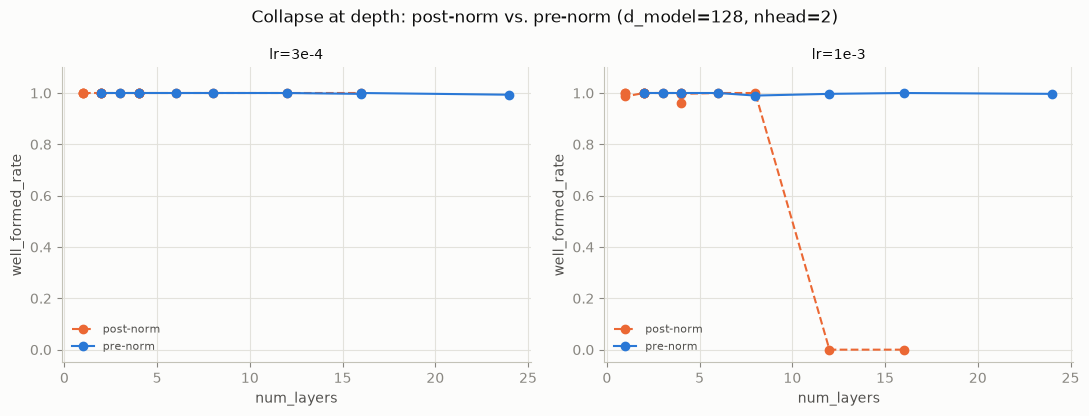

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
fig.patch.set_facecolor(INK["surface"])

for ax, lr, title in zip(axes, [3e-4, 1e-3], ["lr=3e-4", "lr=1e-3"]):
    post_lr = post[post.lr == lr].sort_values("num_layers")
    pre_lr = pre[(pre.nhead == 2) & (pre.lr == lr)].sort_values("num_layers")
    ax.plot(post_lr.num_layers, post_lr.well_formed_rate, "o--", color=CATEGORICAL[1],
            label="post-norm", markersize=6)
    ax.plot(pre_lr.num_layers, pre_lr.well_formed_rate, "o-", color=CATEGORICAL[0],
            label="pre-norm", markersize=6)
    ax.set_xlabel("num_layers")
    ax.set_ylabel("well_formed_rate")
    ax.set_ylim(-0.05, 1.1)
    ax.set_title(title, color=INK["primary"], fontsize=10)
    ax.legend(frameon=False, labelcolor=INK["secondary"], fontsize=8)
    style_axis(ax)
fig.suptitle("Collapse at depth: post-norm vs. pre-norm (d_model=128, nhead=2)", color=INK["primary"])
fig.tight_layout()
plt.show()

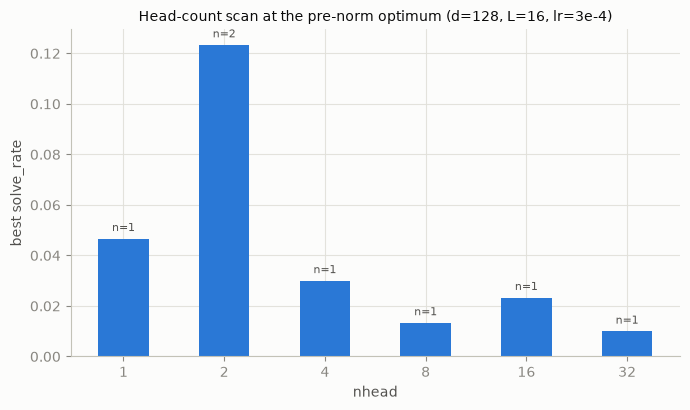

,nhead,mean,max,count
0,1,0.046667,0.046667,1
1,2,0.083333,0.123333,2
2,4,0.030000,0.030000,1
3,8,0.013333,0.013333,1
4,16,0.023333,0.023333,1
5,32,0.010000,0.010000,1


In [5]:
fig, ax = plt.subplots(figsize=(7, 4.2))
fig.patch.set_facecolor(INK["surface"])
nhead_scan = pre[(pre.num_layers == 16) & (pre.lr == 3e-4)].groupby("nhead").solve_rate.agg(["mean", "max", "count"]).reset_index()
ax.bar(nhead_scan.nhead.astype(str), nhead_scan["max"], color=CATEGORICAL[0], width=0.5)
for i, row in nhead_scan.iterrows():
    ax.text(i, row["max"] + 0.003, f"n={int(row['count'])}", ha="center", color=INK["secondary"], fontsize=8)
ax.set_xlabel("nhead")
ax.set_ylabel("best solve_rate")
ax.set_title("Head-count scan at the pre-norm optimum (d=128, L=16, lr=3e-4)", color=INK["primary"], fontsize=10)
style_axis(ax)
fig.tight_layout()
plt.show()
nhead_scan

## Takeaways

1. **Hypothesis confirmed**: pre-norm fixes the depth collapse reproducibly (22/22 configs
   well-formed vs. 0% at the two failure points under post-norm) -- robust.
2. **New best solve_rate is 12.3%** (`d=128, h=2, L=16, lr=3e-4`), up from 7.0% -- but a
   repeat run at the identical config landed at 4.3%, so treat the *peak* number as noisy;
   the *typical* level at this config/depth is more like mid-single-digits to ~12%, not a
   precisely reproducible 12.3%.
3. Head count: 1-2 heads best, declining as head count grows (consistent with every prior
   head-count scan in this project, both encodings).
4. **Not yet at the goal** (>=50% solve_rate) -- still an open problem. Next hypothesis to
   test: explicit `[SATISFIED]`/`[REACTIVATED]` clause-status tokens (see STATUS.md).